# 3.8 What will ECDA's planned centres do?

The prof's follow-up question: will the new centres help, and whom will they attract? For each of
the 13 centres ECDA lists as upcoming (layer `planned`, verified by Jessie), using the 2SFCA of 3.7
(10-minute walk, one unit per centre, HDB children 0-6 as demand):

- **attract** - the children 0-6 in HDB blocks within 10 minutes of the planned centre, and where that
  pool sits among the pools of the 1,796 existing centres;
- **improve** - the pressure of its own subzone before and after adding only that centre, the blocks
  and children whose supply ratio rises, and the subzone that gains most;
- **gap** - the weak-link subzones (top 15 by pressure, or LISA high-high) with no planned centre within
  10 minutes of their children: what the current pipeline leaves untouched.

Code: Minh's `scripts/planned_centre_impact.py`, the planned-centre map from
`scripts/make_pressure_figures.py` and the relief chart from `scripts/make_deck_figures.py`.
Caveats: capacity unknown (one unit per centre); demand pool is HDB children only; the planned list
is ECDA's as of October 2026.

**Inputs**
- `large_data/walk_centres_time_min.parquet`, `large_data/walk_planned_time_min.parquet` (read-only).
- `output/hdb_access_children.csv` (stage 1); `output/childcare_centres_2026.gpkg` layers `centres`, `planned`.
- `output/subzone_pressure.csv`, gpkg layer `subzone_pressure`, `output/weak_links_top15.csv` (3.7).

**Outputs**
- `output/planned_centre_impact.csv` (one row per planned centre), `output/planned_centre_gap.csv`.
- `figures/planned_centres_on_pressure.png`, `figures/planned_centre_relief.png`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio

from bt4015.maps import INK, INK2, INK3, ORANGE, base_map, choropleth, numbered_key, pressure_bins, tidy, use_deck_style
from bt4015.sfca import load_centres, two_sfca, wmean

use_deck_style()
GPKG = OUT / "hdb_blocks.gpkg"
CENTRES_GPKG = OUT / "childcare_centres_2026.gpkg"
D0 = 10            # catchment in walking minutes (same as 3.7)
REACH_SHARE = 0.05 # a weak link counts as "untouched" if under 5% of its children have a planned centre within D0

## 1. Baseline: existing centres and their pools

In [2]:
def subzone_pressure(A, blk):
    """Children-weighted supply ratio per subzone -> children per reachable centre."""
    g = pd.DataFrame({"A": A.reindex(blk.index), "w": blk["child_0_6"], "sz": blk["SUBZONE_C"]})
    m = g.groupby("sz").apply(lambda d: wmean(d["A"], d["w"]))
    return 1 / m.where(m > 0)


# 1. Matrices, planned layer keyed by tp_code, demand per block, subzone names.
T = pd.read_parquet(LARGE / "walk_centres_time_min.parquet")
TP = pd.read_parquet(LARGE / "walk_planned_time_min.parquet").reindex(T.index)
planned, pids = load_centres(CENTRES_GPKG, "planned", matrix_columns=TP.columns)
planned = planned.set_index(pd.Index(pids, name="tp_code"))
blk = pd.read_csv(OUT / "hdb_access_children.csv").set_index("OBJECTID").reindex(T.index)
demand = blk["child_0_6"]
names = pyogrio.read_dataframe(GPKG, layer="subzones", read_geometry=False, columns=["SUBZONE_C", "SUBZONE_N"]).set_index("SUBZONE_C")["SUBZONE_N"]
print(f"{T.shape[0]:,} blocks; {T.shape[1]:,} existing and {TP.shape[1]} planned centres; children 0-6 = {demand.sum():,.0f}")

# 2. Baseline 2SFCA and subzone pressure; distribution of existing pools for the percentile.
A0, R0, pool0 = two_sfca(T, demand, D0)
P0 = subzone_pressure(A0, blk)
existing_pools = pool0[pool0 > 0]
print(f"existing centres: pool within {D0} min median {existing_pools.median():,.0f} children 0-6, "
      f"p90 {existing_pools.quantile(.9):,.0f}, max {existing_pools.max():,.0f} ({len(existing_pools):,} centres with HDB demand in reach)")

10,769 blocks; 1,796 existing and 13 planned centres; children 0-6 = 176,409
existing centres: pool within 10 min median 768 children 0-6, p90 1,983, max 3,673 (1,559 centres with HDB demand in reach)


## 2. One planned centre at a time

Each centre is added alone to the existing 1,796 and the index recomputed, so the effects are not
confounded by the other planned centres.

In [3]:
rows = []
for k in pids:
    # 1. Add this one centre; recompute A, pools and subzone pressure.
    Tk = pd.concat([T, TP[[k]]], axis=1)
    A1, R1, pool1 = two_sfca(Tk, demand, D0)
    P1 = subzone_pressure(A1, blk)
    own = planned.loc[k, "SUBZONE_C"]
    gain = (A1 - A0)
    benefit = gain > 1e-12
    dP = (P1 / P0 - 1) * 100
    best = dP.idxmin() if dP.notna().any() else None
    rows.append({
        "tp_code": k, "service_model": planned.loc[k, "service_model"],
        "centre_name": planned.loc[k, "centre_name"] if str(planned.loc[k, "centre_name"]).lower() not in ("na", "nan", "")
        else f"(unnamed ECDA entry, see evidence: {str(planned.loc[k, 'evidence'])[:50]})",
        "SUBZONE_N": planned.loc[k, "SUBZONE_N"], "PLN_AREA_N": planned.loc[k, "PLN_AREA_N"],
        "expected_opening": planned.loc[k, "expected_opening"],
        "pool_children_0_6": float(pool1[k]),
        "pool_percentile_vs_existing": float((existing_pools < pool1[k]).mean() * 100),
        "own_subzone_pressure_before": float(P0.get(own, np.nan)), "own_subzone_pressure_after": float(P1.get(own, np.nan)),
        "own_subzone_pct_change": float(dP.get(own, np.nan)),
        "blocks_benefiting": int(benefit.sum()), "children_benefiting": float(demand[benefit].sum()),
        "subzones_affected": int((dP < -0.5).sum()),
        "most_improved_subzone": names.get(best, best) if best is not None else None,
        "most_improved_pct_change": float(dP.min()) if best is not None else np.nan,
    })
imp = pd.DataFrame(rows).sort_values("own_subzone_pct_change")
imp.to_csv(OUT / "planned_centre_impact.csv", index=False)
print("Planned centres, sorted by relief in their own subzone:")
print(imp[["centre_name", "SUBZONE_N", "expected_opening", "pool_children_0_6", "pool_percentile_vs_existing",
           "own_subzone_pressure_before", "own_subzone_pct_change", "children_benefiting", "most_improved_subzone",
           "most_improved_pct_change"]].round(1).to_string(index=False))
print(f"\nchildren within {D0} min of at least one planned centre: {demand[(TP <= D0).any(axis=1)].sum():,.0f} "
      f"({100 * demand[(TP <= D0).any(axis=1)].sum() / demand.sum():.1f}% of all HDB children 0-6)")

Planned centres, sorted by relief in their own subzone:
                                                                           centre_name      SUBZONE_N expected_opening  pool_children_0_6  pool_percentile_vs_existing  own_subzone_pressure_before  own_subzone_pct_change  children_benefiting most_improved_subzone  most_improved_pct_change
                               PCF Sparkletots Preschool @ Geylang Serai Blk 182B (CC)       TAI SENG          Q4 2026              516.5                         34.4                        151.4                   -21.6                516.5              TAI SENG                     -21.6
                                                                        MY FIRST SKOOL         GARDEN          Q1 2027              934.9                         60.3                        361.3                   -16.1                934.9                GARDEN                     -16.1
(unnamed ECDA entry, see evidence: ECDA upcoming: Kent Height, Blk 55A Owen R

## 3. The gap: weak links without a planned centre in reach

A weak link is a subzone in 3.7's top 15 by pressure or in its high-high cluster. For each, the share
of its children with any planned centre within 10 minutes; below 5% counts as untouched.

In [4]:
top = pd.read_csv(OUT / "weak_links_top15.csv")
sp = pd.read_csv(OUT / "subzone_pressure.csv")
weak = set(top["SUBZONE_C"]) | set(sp.loc[sp["lisa_q"].eq("HH"), "SUBZONE_C"])
reach = (TP <= D0).any(axis=1)                      # block has a planned centre within D0
per_sz = pd.DataFrame({"sz": blk["SUBZONE_C"], "w": demand, "reach": reach.reindex(blk.index).fillna(False)})
cover = per_sz.groupby("sz").apply(lambda d: d.loc[d["reach"], "w"].sum() / d["w"].sum() if d["w"].sum() else np.nan)
gap = sp[sp["SUBZONE_C"].isin(weak)][["SUBZONE_C", "SUBZONE_N", "PLN_AREA_N", "children_0_6", "pressure_base",
                                      "lisa_q", "planned_centres_n"]].copy()
gap["share_children_near_planned"] = gap["SUBZONE_C"].map(cover).fillna(0)
gap = gap.sort_values("pressure_base", ascending=False)
gap.to_csv(OUT / "planned_centre_gap.csv", index=False)
untouched = gap[gap["share_children_near_planned"] < REACH_SHARE]
print(gap.round(2).to_string(index=False))
print(f"\nWeak links (top 15 or HH): {len(gap)}; with no planned centre within {D0} min of (almost) any child: "
      f"{len(untouched)} -> " + ", ".join(untouched["SUBZONE_N"].str.title()))

SUBZONE_C           SUBZONE_N  PLN_AREA_N  children_0_6  pressure_base lisa_q  planned_centres_n  share_children_near_planned
   TMSZ01      TAMPINES NORTH    TAMPINES       6838.36         595.77     ns                  1                         0.40
   THSZ05              GARDEN      TENGAH       1203.85         361.32     HH                  1                         0.50
   THSZ06          PLANTATION      TENGAH       1960.00         344.52     HH                  1                         0.22
   THSZ03                PARK      TENGAH       1230.00         317.68     HH                  0                         0.00
   BKSZ01              GOMBAK BUKIT BATOK        222.73         309.32     ns                  0                         0.00
   SBSZ01      SEMBAWANG EAST   SEMBAWANG       2336.25         246.43     ns                  0                         0.00
   WDSZ06      WOODLANDS WEST   WOODLANDS       2205.79         240.72     ns                  0                      

## 4. Figures

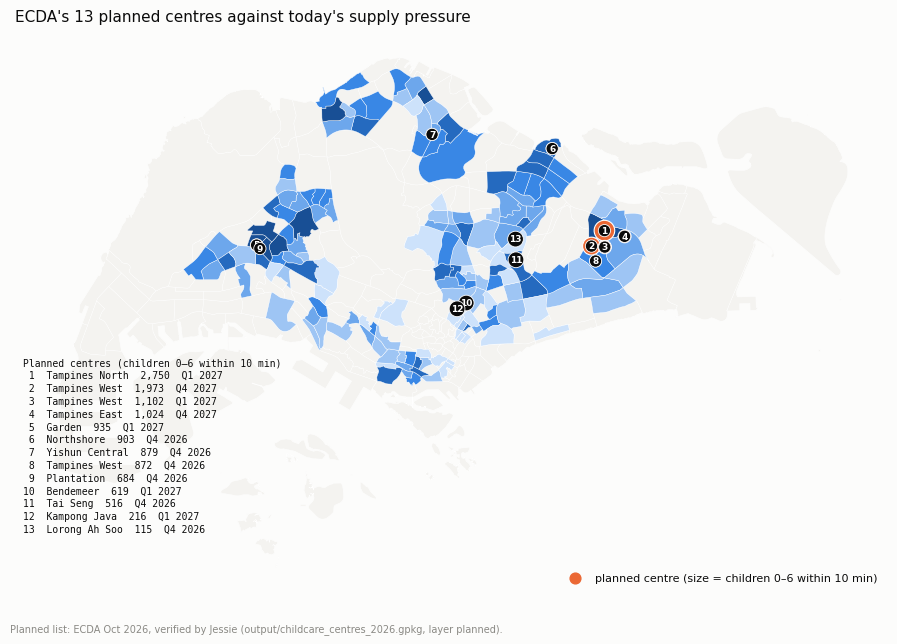

In [5]:
sz_all = pyogrio.read_dataframe(GPKG, layer="subzones")
spg = pyogrio.read_dataframe(GPKG, layer="subzone_pressure")
h = spg[spg["has_hdb"] & spg["pressure_base"].notna()]
bins = pressure_bins(h["pressure_base"])
pl = pyogrio.read_dataframe(CENTRES_GPKG, layer="planned").merge(imp[["tp_code", "pool_children_0_6"]], on="tp_code")
fig, ax = plt.subplots(figsize=(9, 6.5))
base_map(ax, sz_all)
choropleth(ax, h, "pressure_base", "ECDA's 13 planned centres against today's supply pressure", bins)
pl.plot(ax=ax, color=ORANGE, markersize=np.clip(pl["pool_children_0_6"] / 12, 12, 220), edgecolor="white", linewidth=0.8, zorder=5)
pl = pl.sort_values("pool_children_0_6", ascending=False).reset_index(drop=True)
numbered_key(ax, pl, "Planned centres (children 0–6 within 10 min)", point=True,
             extra=lambda r: f"{r['pool_children_0_6']:,.0f}  {r['expected_opening']}", loc=(0.01, 0.42))
ax.scatter([], [], color=ORANGE, s=60, label="planned centre (size = children 0–6 within 10 min)")
ax.legend(loc="lower right", frameon=False, fontsize=8)
fig.text(0.01, 0.01, "Planned list: ECDA Oct 2026, verified by Jessie (output/childcare_centres_2026.gpkg, layer planned).", fontsize=7, color=INK3)
fig.tight_layout()
fig.savefig(FIG / "planned_centres_on_pressure.png", dpi=170)
plt.show()

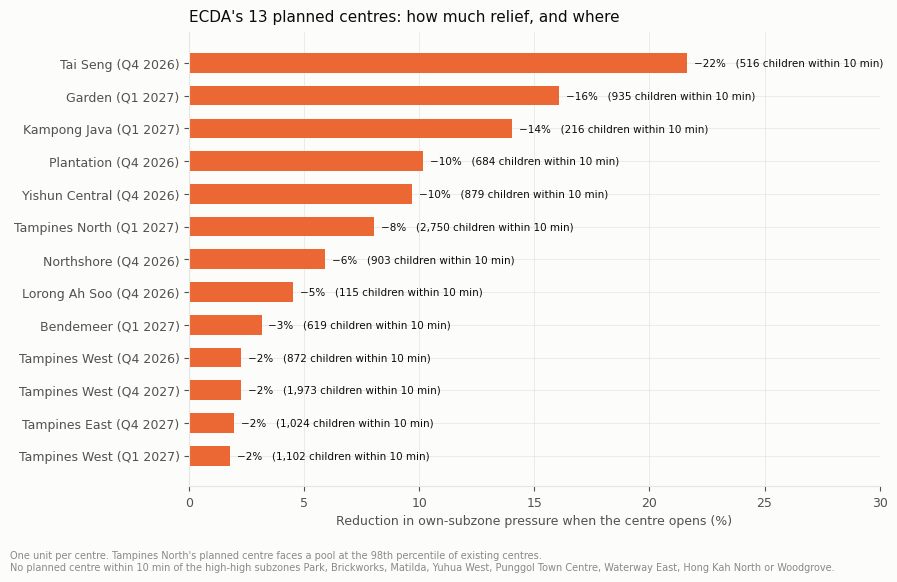

In [6]:
imp_sorted = imp.sort_values("own_subzone_pct_change")
lab = [f"{r.SUBZONE_N.title()} ({r.expected_opening})" for r in imp_sorted.itertuples()]
untouched_hh = untouched[untouched["lisa_q"].eq("HH")]["SUBZONE_N"].str.title().tolist()
fig, ax = plt.subplots(figsize=(9, 5.8))
ax.barh(lab, -imp_sorted["own_subzone_pct_change"], color=ORANGE, height=0.6)
for k, (v, pool) in enumerate(zip(imp_sorted["own_subzone_pct_change"], imp_sorted["pool_children_0_6"])):
    ax.text(-v + 0.3, k, f"−{-v:.0f}%   ({pool:,.0f} children within 10 min)", va="center", fontsize=7.5, color=INK)
ax.invert_yaxis(); ax.set_xlim(0, 30)
ax.set_xlabel("Reduction in own-subzone pressure when the centre opens (%)")
ax.set_title("ECDA's 13 planned centres: how much relief, and where", loc="left", fontsize=11, pad=8)
tidy(ax)
tn = imp[imp["SUBZONE_N"].eq("TAMPINES NORTH")].iloc[0]
fig.text(0.01, 0.01, f"One unit per centre. Tampines North's planned centre faces a pool at the {tn['pool_percentile_vs_existing']:.0f}th percentile of existing centres.\n"
         f"No planned centre within 10 min of the high-high subzones {', '.join(untouched_hh[:-1])} or {untouched_hh[-1]}.", fontsize=7, color=INK3)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIG / "planned_centre_relief.png", dpi=170)
plt.show()

## 5. Findings and files

The Tampines North centre has by far the largest catchment (about 2,750 children, the 98th percentile
of existing centres) and still only cuts that subzone's pressure by 8%, because 10 centres already
share 6,800 children there. The Tengah centres (Garden, Plantation) give the largest relative relief
in the high-high cluster. But most of the weak links get nothing: 16 of the 20 weak-link subzones have
no planned centre within 10 minutes of their children, including Park, Brickworks, Matilda, Sembawang
East, Woodlands West and Yishun East. That list is the answer to "where is the best place to start a
new centre".

In [7]:
print(f"output/planned_centre_impact.csv: {len(imp)} rows; output/planned_centre_gap.csv: {len(gap)} rows "
      f"({len(untouched)} untouched)")
print("figures/planned_centres_on_pressure.png, figures/planned_centre_relief.png")

output/planned_centre_impact.csv: 13 rows; output/planned_centre_gap.csv: 20 rows (16 untouched)
figures/planned_centres_on_pressure.png, figures/planned_centre_relief.png
